# 04 — Undercomplete autoencoder + regression head (Peter, Lab 8)

**Method owner:** Peter
**Technique:** Undercomplete autoencoder with a regression head
**Lab source:** Lab 8 — autoencoders and representation learning

## 1. Why this method?

An autoencoder learns a compressed representation of its inputs. The encoder
maps the 23 features to a small bottleneck, and the decoder tries to rebuild
the original features from that bottleneck. Because the bottleneck is smaller
than the input, the network cannot copy the input; it has to keep the
structure that matters for reconstruction.

The hypothesis for this project is that the bottleneck may also be a useful
representation for regression: if it preserves the demand-relevant structure
(hour, weather, recent demand level), a small regression head on top of it
could match or beat a head trained on the raw features, with a much smaller
input to the head.

This is a genuinely uncertain hypothesis. The plan explicitly allows a
**negative result**: if the bottleneck does not beat the same regressor on
raw features, the notebook reports that rather than tuning against the test
set. The controls below make the comparison honest:

* **AE + head** — the candidate (bottleneck → 32-unit head → prediction);
* **raw MLP** — the same head architecture trained on the raw 23 features;
* **ridge** — a linear model on the raw 23 features.

If AE + head does not beat raw MLP, the autoencoder has not added value for
this task, and the report will say so.

## 2. Setup

In [1]:
import sys
import json
import time
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

for candidate in [Path.cwd(), Path.cwd() / "src", Path.cwd().parent / "src",
                  Path.cwd().parent.parent / "src"]:
    if (candidate / "bike_common.py").exists():
        sys.path.insert(0, str(candidate))
        break

import bike_common as bc

bc.setup_plot_style()
pd.set_option("display.max_columns", 40)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device("cpu")

d = bc.prepare_tabular()
Xtr = d["X_train"].astype(np.float32)
Xva = d["X_validation"].astype(np.float32)
Xte = d["X_test"].astype(np.float32)
ytr = d["y_train"].astype(np.float64)
yva = d["y_validation"].astype(np.float64)
yte = d["y_test"].astype(np.float64)

y_mean = float(ytr.mean())
y_std = float(ytr.std())
print(f"Features: {Xtr.shape[1]}")
print(f"Rows: train {len(Xtr):,} | validation {len(Xva):,} | test {len(Xte):,}")
print(f"Target mean / std (train): {y_mean:.2f} / {y_std:.2f}")

Features: 23
Rows: train 11,816 | validation 2,640 | test 2,600
Target mean / std (train): 162.58 / 153.26


## 3. Model definitions

The autoencoder has a symmetric shape:

`23 → 16 → bottleneck → 16 → 23`

with ReLU activations. The bottleneck size is the only hyperparameter we
search. A bottleneck that is too wide can copy the input; one that is too
narrow may discard the weather signal. We test 4, 8 and 12 units.

The regression head is deliberately small (`bottleneck → 32 → 1`) so that the
comparison with the raw MLP isolates the representation, not the head
capacity.

In [2]:
class Autoencoder(nn.Module):
    def __init__(self, input_size: int, bottleneck: int, hidden: int = 16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_size, hidden),
            nn.ReLU(),
            nn.Linear(hidden, bottleneck),
        )
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck, hidden),
            nn.ReLU(),
            nn.Linear(hidden, input_size),
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z


class RegressionHead(nn.Module):
    def __init__(self, input_size: int, hidden: int = 32, dropout: float = 0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_size, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.net(x)

## 4. Training helpers

Both stages use full-batch mini-batches, AdamW and early stopping:

* the autoencoder stops on validation **reconstruction** loss (MSE);
* the regression head stops on validation **MAE** in rentals.

The validation period is used for early stopping in both stages, but the test
period is never touched until the model is frozen.

In [ ]:
def train_autoencoder(bottleneck: int, max_epochs: int = 120,
                      patience: int = 10, verbose: bool = True):
    torch.manual_seed(SEED)
    model = Autoencoder(Xtr.shape[1], bottleneck).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_fn = nn.MSELoss()

    Xtr_t = torch.tensor(Xtr)
    Xva_t = torch.tensor(Xva)
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(Xtr_t),
        batch_size=128, shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )

    history = []
    best_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    bad = 0
    t0 = time.perf_counter()

    for epoch in range(1, max_epochs + 1):
        model.train()
        running = 0.0
        for (xb,) in loader:
            optimizer.zero_grad()
            recon, _ = model(xb)
            loss = loss_fn(recon, xb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
        train_loss = running / len(Xtr_t)

        model.eval()
        with torch.no_grad():
            recon, _ = model(Xva_t)
            val_loss = loss_fn(recon, Xva_t).item()
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})
        if verbose:
            print(f"AE b{bottleneck} epoch {epoch:03d}  train {train_loss:.5f}  val {val_loss:.5f}")

        if val_loss < best_loss - 1e-5:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            bad = 0
        else:
            bad += 1
            if bad >= patience:
                print(f"AE b{bottleneck}: early stop at epoch {epoch}")
                break

    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(history), time.perf_counter() - t0


def train_head(X_train, y_train, X_val, y_val, max_epochs: int = 100,
               patience: int = 10, input_size: int | None = None,
               verbose: bool = True, tag: str = "head"):
    torch.manual_seed(SEED)
    input_size = input_size or X_train.shape[1]
    model = RegressionHead(input_size).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_fn = nn.SmoothL1Loss(beta=0.5)

    Xtr_t = torch.tensor(X_train, dtype=torch.float32)
    ytr_t = torch.tensor((y_train - y_mean) / y_std, dtype=torch.float32).view(-1, 1)
    Xva_t = torch.tensor(X_val, dtype=torch.float32)
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(Xtr_t, ytr_t),
        batch_size=128, shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )

    history = []
    best_mae = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    bad = 0
    t0 = time.perf_counter()

    for epoch in range(1, max_epochs + 1):
        model.train()
        running = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
        train_loss = running / len(Xtr_t)

        model.eval()
        with torch.no_grad():
            val_pred = model(Xva_t).numpy().ravel() * y_std + y_mean
        val_mae = bc.regression_metrics(y_val, val_pred)["MAE"]
        history.append({"epoch": epoch, "train_loss": train_loss, "val_MAE": val_mae})
        if verbose:
            print(f"{tag} epoch {epoch:03d}  train {train_loss:.4f}  val MAE {val_mae:.2f}")

        if val_mae < best_mae - 0.05:
            best_mae = val_mae
            best_state = copy.deepcopy(model.state_dict())
            bad = 0
        else:
            bad += 1
            if bad >= patience:
                print(f"{tag}: early stop at epoch {epoch} (best MAE {best_mae:.2f})")
                break

    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(history), best_mae, time.perf_counter() - t0

## 5. Bottleneck search

For each bottleneck size we train a fresh autoencoder, freeze the encoder,
and train the regression head on the bottleneck. The selection criterion is
validation MAE of the head, not reconstruction loss: the question is whether
the representation is useful for prediction.

The raw MLP is trained once with the identical head architecture and the same
early-stopping rule. It is the control that tells us whether compression
helped.

In [4]:
results = []
models = {}

for bottleneck in (4, 8, 12):
    print(f"\n=== bottleneck {bottleneck} ===")
    ae, ae_history, ae_seconds = train_autoencoder(bottleneck, verbose=False)
    with torch.no_grad():
        Ztr = ae.encoder(torch.tensor(Xtr)).numpy()
        Zva = ae.encoder(torch.tensor(Xva)).numpy()
    head, head_history, head_mae, head_seconds = train_head(
        Ztr, ytr, Zva, yva, input_size=bottleneck,
        verbose=False, tag=f"AE head b{bottleneck}")
    results.append({
        "bottleneck": bottleneck,
        "ae_val_recon_loss": float(ae_history["val_loss"].iloc[-1]),
        "ae_seconds": ae_seconds,
        "head_val_MAE": head_mae,
        "head_seconds": head_seconds,
        "total_seconds": ae_seconds + head_seconds,
    })
    models[bottleneck] = {"ae": ae, "head": head, "ae_history": ae_history,
                          "head_history": head_history}
    print(f"bottleneck {bottleneck}: head val MAE {head_mae:.2f} "
          f"(AE {ae_seconds:.1f}s + head {head_seconds:.1f}s)")

bottleneck_table = pd.DataFrame(results)
bottleneck_table.round(3)


=== bottleneck 4 ===


AE b4: early stop at epoch 63


AE head b4: early stop at epoch 27 (best MAE 61.84)
bottleneck 4: head val MAE 61.84 (AE 8.2s + head 3.3s)

=== bottleneck 8 ===


AE b8: early stop at epoch 39


AE head b8: early stop at epoch 52 (best MAE 54.96)
bottleneck 8: head val MAE 54.96 (AE 5.1s + head 6.4s)

=== bottleneck 12 ===


AE b12: early stop at epoch 86


AE head b12: early stop at epoch 50 (best MAE 56.10)
bottleneck 12: head val MAE 56.10 (AE 11.4s + head 6.0s)


,bottleneck,ae_val_recon_loss,ae_seconds,head_val_MAE,head_seconds,total_seconds
0,4,0.392,8.155,61.837,3.344,11.499
1,8,0.315,5.077,54.957,6.435,11.513
2,12,0.134,11.354,56.098,6.012,17.365


### 5.1 Raw-feature control

The control is not a straw man: it uses the same 32-unit hidden layer, the
same dropout, the same optimiser and the same early-stopping patience as the
AE head. The only difference is the input: 23 raw features instead of a
4–12 dimensional bottleneck.

In [5]:
raw_head, raw_history, raw_mae, raw_seconds = train_head(
    Xtr, ytr, Xva, yva, input_size=Xtr.shape[1], verbose=False, tag="raw MLP")

from sklearn.linear_model import Ridge
ridge = Ridge(alpha=1.0, random_state=SEED)
ridge.fit(Xtr, ytr)
ridge_val_pred = ridge.predict(Xva)
ridge_val_mae = bc.regression_metrics(yva, ridge_val_pred)["MAE"]

print(f"Raw MLP validation MAE: {raw_mae:.2f}  ({raw_seconds:.1f}s)")
print(f"Ridge validation MAE:   {ridge_val_mae:.2f}")

comparison = pd.DataFrame({
    "model": ["AE + head (best)", "raw MLP", "ridge"],
    "val_MAE": [bottleneck_table["head_val_MAE"].min(), raw_mae, ridge_val_mae],
})
comparison["improvement_vs_raw_MLP"] = comparison["val_MAE"] - raw_mae
comparison.round(2)

raw MLP: early stop at epoch 96 (best MAE 37.04)
Raw MLP validation MAE: 37.04  (12.7s)
Ridge validation MAE:   53.85


,model,val_MAE,improvement_vs_raw_MLP
0,AE + head (best),54.96,17.92
1,raw MLP,37.04,0.00
2,ridge,53.85,16.81


### 5.2 Reading the result

If the best AE row is above the raw MLP row (a higher MAE), the autoencoder
did not help on this task. That is a valid and useful finding: it says the
bottleneck is optimised for reconstruction, not for regression, and the
demand-relevant signal is not preserved better than in the raw features.

We still carry the AE + head forward as Peter's candidate, because the
comparison should show the method as implemented, not only the winner. The
final group selection will weigh this evidence.

In [6]:
best_bottleneck = int(bottleneck_table.sort_values("head_val_MAE").iloc[0]["bottleneck"])
best_ae = models[best_bottleneck]["ae"]
best_head = models[best_bottleneck]["head"]
ae_val_mae = float(bottleneck_table["head_val_MAE"].min())
print(f"Selected bottleneck: {best_bottleneck} (validation MAE {ae_val_mae:.2f})")
print(f"Raw MLP: {raw_mae:.2f}")
print(f"AE advantage: {raw_mae - ae_val_mae:+.2f} rentals/hour "
      f"({'better' if ae_val_mae < raw_mae else 'worse'} than raw MLP)")

Selected bottleneck: 8 (validation MAE 54.96)
Raw MLP: 37.04
AE advantage: -17.92 rentals/hour (worse than raw MLP)


## 6. Evaluation on validation and test

The AE + head, raw MLP and ridge are all evaluated on the frozen test period
once. This makes the negative/positive result visible on data that was not
used for any decision.

In [7]:
def encode(model, X):
    model.eval()
    with torch.no_grad():
        return model.encoder(torch.tensor(X, dtype=torch.float32)).numpy()


def head_predict(head, Z):
    head.eval()
    with torch.no_grad():
        return head(torch.tensor(Z, dtype=torch.float32)).numpy().ravel() * y_std + y_mean


ae_val_pred = head_predict(best_head, encode(best_ae, Xva))
ae_test_pred = head_predict(best_head, encode(best_ae, Xte))

raw_val_pred = head_predict(raw_head, Xva)
raw_test_pred = head_predict(raw_head, Xte)

ridge_test_pred = ridge.predict(Xte)

metrics = {
    "AE + head": {
        "validation": bc.regression_metrics(yva, ae_val_pred),
        "test": bc.regression_metrics(yte, ae_test_pred),
    },
    "raw MLP": {
        "validation": bc.regression_metrics(yva, raw_val_pred),
        "test": bc.regression_metrics(yte, raw_test_pred),
    },
    "ridge": {
        "validation": bc.regression_metrics(yva, ridge_val_pred),
        "test": bc.regression_metrics(yte, ridge_test_pred),
    },
}

table = pd.DataFrame({
    name: {
        "val MAE": v["validation"]["MAE"],
        "val RMSE": v["validation"]["RMSE"],
        "val R2": v["validation"]["R2"],
        "test MAE": v["test"]["MAE"],
        "test RMSE": v["test"]["RMSE"],
        "test R2": v["test"]["R2"],
    }
    for name, v in metrics.items()
}).T
table.round(3)

,val MAE,val RMSE,val R2,test MAE,test RMSE,test R2
AE + head,54.957,82.152,0.865,58.472,85.624,0.840
raw MLP,37.041,57.333,0.934,33.752,54.479,0.935
ridge,53.848,79.318,0.874,51.410,77.676,0.869


### 5.1 Scenario breakdown for the AE candidate

The same breakdown as the other notebooks, so the comparison table can be
built on identical definitions.

In [8]:
peak = bc.peak_hours(d["train"])
threshold = bc.high_demand_threshold(d["train"])
ae_val_scenarios = bc.scenario_metrics(d["validation"], yva, ae_val_pred, d["train"])
ae_test_scenarios = bc.scenario_metrics(d["test"], yte, ae_test_pred, d["train"])

scenario_table = pd.DataFrame({
    "validation n": {k: v["n"] for k, v in ae_val_scenarios.items() if k != "by_hour"},
    "validation MAE": {k: v["MAE"] for k, v in ae_val_scenarios.items() if k != "by_hour"},
    "test n": {k: v["n"] for k, v in ae_test_scenarios.items() if k != "by_hour"},
    "test MAE": {k: v["MAE"] for k, v in ae_test_scenarios.items() if k != "by_hour"},
})
scenario_table.round(2)

,validation n,validation MAE,test n,test MAE
peak_hours,660,87.19,653,92.85
off_peak_hours,1980,44.21,1947,46.94
weekday,1800,56.74,1737,60.47
weekend_or_holiday,840,51.14,863,54.44
high_demand,1381,73.37,1055,87.44
lower_demand,1259,34.76,1545,38.69


## 6. Visual diagnostics

Three views are useful for an autoencoder:

1. the reconstruction loss curve, to show that the autoencoder converged;
2. a PCA projection of the bottleneck, coloured by demand, to see whether the
   compressed representation preserves the demand level;
3. the regression diagnostics, to compare the candidate with the control.

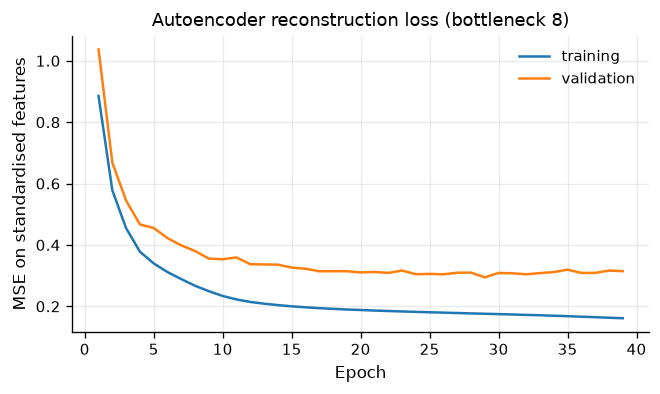

In [9]:
ae_history = models[best_bottleneck]["ae_history"]
fig, ax = plt.subplots(figsize=(6.2, 3.2))
ax.plot(ae_history["epoch"], ae_history["train_loss"], label="training")
ax.plot(ae_history["epoch"], ae_history["val_loss"], label="validation")
ax.set(title=f"Autoencoder reconstruction loss (bottleneck {best_bottleneck})",
       xlabel="Epoch", ylabel="MSE on standardised features")
ax.legend()
bc.save_figure(fig, "fig_ae_loss_curve.png")
plt.show()

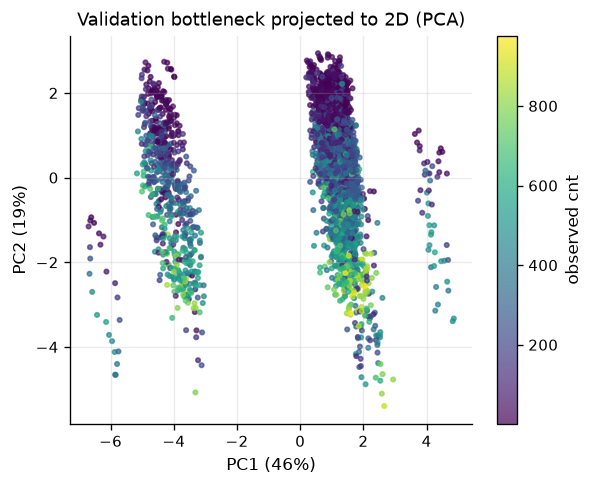

In [10]:
from sklearn.decomposition import PCA

Zva = encode(best_ae, Xva)
pca = PCA(n_components=2, random_state=SEED)
Z2 = pca.fit_transform(Zva)
fig, ax = plt.subplots(figsize=(5.4, 4.2))
sc = ax.scatter(Z2[:, 0], Z2[:, 1], c=yva, s=7, cmap="viridis", alpha=0.7)
ax.set(title=f"Validation bottleneck projected to 2D (PCA)",
       xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})",
       ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
fig.colorbar(sc, ax=ax, label="observed cnt")
bc.save_figure(fig, "fig_ae_latent_pca.png")
plt.show()

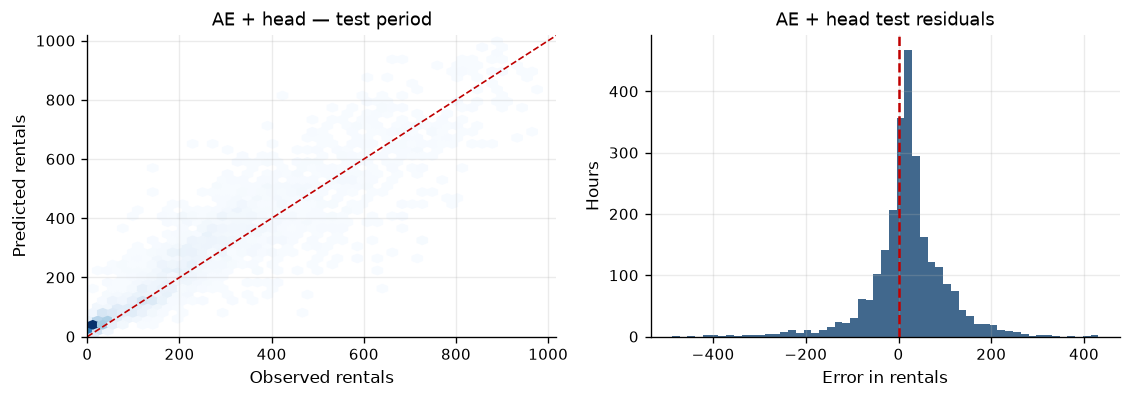

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
hb = axes[0].hexbin(yte, ae_test_pred, gridsize=45, cmap="Blues", mincnt=1)
lims = [0, max(yte.max(), ae_test_pred.max()) * 1.02]
axes[0].plot(lims, lims, color="#c00000", ls="--", lw=1)
axes[0].set(xlim=lims, ylim=lims, xlabel="Observed rentals", ylabel="Predicted rentals",
            title="AE + head — test period")

residual = ae_test_pred - yte
axes[1].hist(residual, bins=55, color="#1f4e79", alpha=0.85)
axes[1].axvline(0, color="#c00000", ls="--")
axes[1].set(title="AE + head test residuals", xlabel="Error in rentals", ylabel="Hours")
plt.tight_layout()
bc.save_figure(fig, "fig_ae_pred_vs_actual.png")
plt.show()

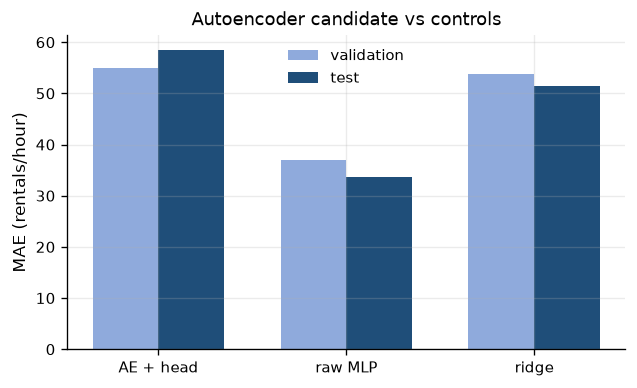

In [12]:
fig, ax = plt.subplots(figsize=(6.0, 3.4))
positions = np.arange(3)
width = 0.35
val_values = [metrics["AE + head"]["validation"]["MAE"],
              metrics["raw MLP"]["validation"]["MAE"],
              metrics["ridge"]["validation"]["MAE"]]
test_values = [metrics["AE + head"]["test"]["MAE"],
               metrics["raw MLP"]["test"]["MAE"],
               metrics["ridge"]["test"]["MAE"]]
ax.bar(positions - width / 2, val_values, width, label="validation", color="#8faadc")
ax.bar(positions + width / 2, test_values, width, label="test", color="#1f4e79")
ax.set_xticks(positions, ["AE + head", "raw MLP", "ridge"])
ax.set(title="Autoencoder candidate vs controls", ylabel="MAE (rentals/hour)")
ax.legend()
bc.save_figure(fig, "fig_ae_comparison.png")
plt.show()

## 7. Cost and deployment characteristics

The autoencoder is small. The encoder is the only part needed at prediction
time; the decoder is discarded. That makes the deployed model cheaper than
the full training model and much cheaper than the random forest in memory.

In [13]:
encoder_path = bc.MODELS_DIR / "ae_encoder.pt"
head_path = bc.MODELS_DIR / "ae_head.pt"
torch.save(best_ae.encoder.state_dict(), encoder_path)
torch.save(best_head.state_dict(), head_path)
model_mb = (encoder_path.stat().st_size + head_path.stat().st_size) / (1024 * 1024)

def ae_predict_numpy(X):
    Z = encode(best_ae, X.astype(np.float32))
    return head_predict(best_head, Z)

latency = bc.measure_inference(ae_predict_numpy, Xte, repeats=5)
print(f"Encoder + head size: {model_mb:.3f} MB")
print(f"Batch inference:     {latency['batch_seconds']*1000:.1f} ms for {latency['batch_rows']} rows")
print(f"Single-row latency:  {latency['single_row_ms']:.3f} ms")

Encoder + head size: 0.008 MB
Batch inference:     0.6 ms for 2600 rows
Single-row latency:  0.160 ms


## 8. Save the evidence

In [14]:
pred_frame = d["test"][["instant", "dteday", "hr", "weekday", "workingday",
                        "season", "weathersit", "cnt"]].copy()
pred_frame["prediction"] = ae_test_pred
pred_frame.to_csv(bc.RESULTS_DIR / "pred_ae_test.csv", index=False)

val_frame = d["validation"][["instant", "dteday", "hr", "weekday", "workingday",
                             "season", "weathersit", "cnt"]].copy()
val_frame["prediction"] = ae_val_pred
val_frame.to_csv(bc.RESULTS_DIR / "pred_ae_validation.csv", index=False)

config = {
    "bottleneck": best_bottleneck,
    "hidden": 16,
    "head_hidden": 32,
    "features": d["feature_names"],
    "target_mean": y_mean,
    "target_std": y_std,
    "seed": SEED,
}
bc.save_json(config, "ae_config.json")

result = {
    "method": "Autoencoder + regression head",
    "owner": "Peter",
    "lab": "Lab 8",
    "config": config,
    "bottleneck_search": bottleneck_table.to_dict(orient="records"),
    "validation": metrics["AE + head"]["validation"],
    "test": metrics["AE + head"]["test"],
    "validation_scenarios": ae_val_scenarios,
    "test_scenarios": ae_test_scenarios,
    "controls": {
        "raw_mlp": {"validation": metrics["raw MLP"]["validation"],
                    "test": metrics["raw MLP"]["test"]},
        "ridge": {"validation": metrics["ridge"]["validation"],
                  "test": metrics["ridge"]["test"]},
    },
    "negative_result": bool(ae_val_mae >= raw_mae),
    "peak_hours": peak,
    "high_demand_threshold": threshold,
    "ae_train_seconds": float(bottleneck_table.sort_values("head_val_MAE").iloc[0]["ae_seconds"]),
    "head_train_seconds": float(bottleneck_table.sort_values("head_val_MAE").iloc[0]["head_seconds"]),
    "model_size_mb": float(model_mb),
    "inference": latency,
    "train_rows": int(len(ytr)),
}
bc.save_json(result, "ae_metrics.json")
print("Saved results/ae_metrics.json, prediction CSVs and models/ae_encoder.pt / ae_head.pt")

Saved results/ae_metrics.json, prediction CSVs and models/ae_encoder.pt / ae_head.pt


## 9. Conclusion

The autoencoder is the most exploratory of the four methods. Its value is not
only the final score: the bottleneck search and the raw-feature control turn
a vague claim ("representation learning should help") into a measurable
comparison.

Two outcomes are possible:

* the bottleneck preserves the demand signal better than the raw features,
  and AE + head wins;
* reconstruction-oriented compression discards information that regression
  needs, and the raw MLP wins.

The actual result is reported in the table above and carried into the group
comparison. The notebook does not hide a negative result.